# Notebook 03 — OD seed matrix (zone level)

Builds the bicycle-commuter **seed matrix** for the study-area cordon from 2016 ABS Journey-to-Work
data. This is the spatial *prior* `n` that Notebook 04 calibrates against the bike counts — it sets the
*shape* of demand, not its magnitude (§4.2.1: the seed is never scaled or divided).

**Zone level only.** Node-level edge distribution, routing feasibility, and the through-trip
cordon-crossing test all happen in Notebook 04 (§4.2.4, §4.4).

**Inputs:** four ABS TableBuilder matrices (SA1→DZN, SA2→DZN inbound, SA1→outside-DZN, SA2→outside-DZN),
the zone-membership CSVs, the cordon entry points + snapping rules, and the ABS DZN polygons.
**Outputs:** `jtw_2016_bike_od_snapped.csv`, `jtw_2016_bike_od_through_raw.csv`, `jtw_2016_points.csv`,
`jtw_2016_zone_centroids.csv`, and `reports/03_od_seed_report.txt`.


## The three commuter movements (§4.2.1)

```mermaid
flowchart LR
    subgraph OUT[Outside cordon]
      SA2[SA2 origins]
      DZNo[outside DZNs]
    end
    subgraph IN[Inside cordon]
      SA1[SA1 origins]
      DZNi[inside DZNs]
    end
    SA1 -->|inbound| DZNi
    SA2 -->|inbound, via entry point| DZNi
    SA1 -->|outbound, to exit point| DZNo
    SA2 -->|through, raw to NB04| DZNo
```

- **Inbound** — destination DZN inside the cordon (origins SA1 inside *and* SA2 outside).
- **Outbound** — origin SA1 inside, destination DZN outside.
- **Through** — both endpoints outside; passed **raw** to Notebook 04, which keeps only pairs whose
  least-cost path actually crosses the cordon.

External origins/destinations don't route from a centroid — they enter/leave at one of the **30 cordon
entry points** (§4.2.4), with a corridor share-split where an SA2 reaches the cordon by more than one crossing.


## Pipeline

```mermaid
flowchart TD
    L[Load zone lists: SA1 in, SA2 out, DZN in] --> P[Parse 4 TableBuilder matrices]
    P --> Z[Zone-to-zone OD + centroids]
    Z --> SNAP[Snap SA2 origins to entry points<br/>share-split + nearest-boundary inherit]
    SNAP --> EXIT[Snap outside DZNs to exit points]
    EXIT --> OD[Snapped OD table]
    Z --> THRU[(through_raw.csv -> NB04)]
    OD --> OUT[(od_snapped.csv, points.csv, centroids.csv)]
```


# A — Setup and configuration


## A.1 Environment and directories

Imports the geospatial/tabular stack and creates the standard project folders (`data/raw`,
`data/processed`, `figures`, `reports`).


In [2]:
import csv, os
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point

# Standard project folder layout (created if missing).
PROJECT_ROOT   = Path(os.getcwd())
DATA_RAW       = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
FIGURES        = PROJECT_ROOT / "figures"
REPORTS        = PROJECT_ROOT / "reports"
for f in (DATA_RAW, DATA_PROCESSED, FIGURES, REPORTS): f.mkdir(parents=True, exist_ok=True)
OUT = DATA_PROCESSED
print("Project root:", PROJECT_ROOT)


Project root: c:\Users\aylex\OneDrive - The University of Sydney (Students)\Thesis A\Python Code\Phase 1 + 2


In [3]:
# ── CONFIG ────────────────────────────────────────────────────
# Four ABS TableBuilder matrices (one per movement source).
SA1_INBOUND_MATRIX  = DATA_RAW / "SA1_to_DZN_20260928.csv"
SA2_INBOUND_MATRIX  = DATA_RAW / "SA2_to_DZN_20260929.csv"
SA1_OUTBOUND_MATRIX = DATA_RAW / "SA1inside_to_DZNoutside_20261002.csv"
SA2_THROUGH_MATRIX  = DATA_RAW / "SA2outside_to_DZNoutside_20261003.csv"

# Zone membership lists
SA1_LIST = DATA_RAW / "SA1s_in_Boundary_Cordon.csv"
SA2_LIST = DATA_RAW / "SA2s_Outside_Boundary_Cordon.csv"
DZN_LIST = DATA_RAW / "DZNs_in_Boundary_Cordon.csv"

# Cordon entry points + corridor share-split rules
ENTRY_POINTS   = DATA_RAW / "cordon_entry_points.csv"
SNAPPING_RULES = DATA_RAW / "snapping_rules.csv"

# ABS DZN polygons (for outside-DZN centroids + cordon outline on maps)
DZN_POLYGONS   = DATA_RAW / "80000_dzn_2016_aust_geopackage" / "ASGS 2016 DZN.gpkg"

CENTROID_CRS  = "EPSG:4326"     # lat/lon for maps
PROJECTED_CRS = "EPSG:28356"    # GDA94/MGA56, metres — used for any centroid/distance
print("Config loaded.")

Config loaded.


## A.2 Zone membership lists


Load the zone definitions (SA1s inside the cordon, external SA2s, internal DZNs) and build the code sets
and name→code lookup used to filter the TableBuilder matrices.


In [4]:
# Zone-membership lists as whitespace-stripped strings (ABS codes must stay strings to keep leading zeros).
sa1 = pd.read_csv(SA1_LIST, dtype=str).apply(lambda c: c.str.strip())
sa2 = pd.read_csv(SA2_LIST, dtype=str).apply(lambda c: c.str.strip())
dzn = pd.read_csv(DZN_LIST, dtype=str).apply(lambda c: c.str.strip())

# Code sets for filtering, plus an SA2 name->code map (TableBuilder labels SA2s by name).
sa1_codes         = set(sa1["SA1_7DIG16"])
dzn_codes_inside  = set(dzn["DZN_CODE_2016"])
sa2_codes_outside = set(sa2["SA2_MAIN16"])
name_to_sa2       = dict(zip(sa2["SA2_NAME16"], sa2["SA2_MAIN16"]))
assert len(name_to_sa2) == len(sa2), "duplicate SA2 names"
print(f"{len(sa1_codes)} SA1s inside | {len(sa2)} SA2s outside | {len(dzn_codes_inside)} DZNs inside")


556 SA1s inside | 563 SA2s outside | 292 DZNs inside


# B — Parse the four TableBuilder matrices


Two helpers: `read_tablebuilder` strips the ABS preamble/metadata and returns a clean wide integer
matrix plus its grand total; `to_long` melts a wide matrix to (origin, destination, trips), keeping only
the target destinations and dropping zero-trip cells.


In [5]:
def read_tablebuilder(path):
    """Raw ABS TableBuilder CSV -> (wide integer DataFrame by row label, grand total)."""
    # utf-8-sig tolerates the BOM/preamble ABS exports carry.
    rows = list(csv.reader(open(path, encoding="utf-8-sig")))
    # The header row is the one whose second cell is the destination-zone label.
    h = next(i for i, r in enumerate(rows) if len(r) > 1 and r[1] == "DZN (POW)")
    cols = [c.strip() for c in rows[h]]
    body, total = [], None
    # Body starts two rows after the header; capture the grand total separately.
    for r in rows[h+2:]:
        if len(r) < 3: continue
        if r[0].strip() == "Total":
            total = int(r[cols.index("Total")]); continue
        body.append([r[0].strip()] + r[2:len(cols)])
    df = pd.DataFrame(body, columns=["label"] + cols[2:]).set_index("label")
    df = df.drop(columns=[c for c in ("Total", "") if c in df.columns])
    return df.apply(pd.to_numeric, errors="coerce").fillna(0).astype(int), total

def to_long(wide, keep, tag):
    """Wide OD matrix -> long (origin, destination, trips), kept to `keep` destinations, zeros dropped."""
    miss = sorted(keep - set(wide.columns))
    if miss: print(f"[{tag}] {len(miss)} target DZNs absent, e.g. {miss[:4]}")
    wide = wide[[c for c in wide.columns if c in keep]]
    lo = (wide.rename_axis("origin").reset_index()
            .melt(id_vars="origin", var_name="destination", value_name="trips"))
    return lo[lo["trips"] > 0]

print("Readers ready.")


Readers ready.


Parse each of the four matrices, filter rows/columns to the relevant zones, and tag the movement class.
Outside-DZN codes are derived from the outbound and through matrices (every column not inside the cordon).


In [6]:
# 1. SA1 inbound: inside SA1 -> inside DZN
# Read the SA1 inbound TableBuilder matrix and filter rows to include only SA1s inside the cordon
w1, tot1 = read_tablebuilder(SA1_INBOUND_MATRIX)
w1 = w1[w1.index.isin(sa1_codes)]
# Convert the wide matrix to long format, keeping only internal destination zones, and tag as internal inbound
od_sa1_in = to_long(w1, dzn_codes_inside, "SA1 inbound"); od_sa1_in["movement"] = "inbound_internal"
print(f"[SA1 inbound ] total {tot1}, kept {od_sa1_in.trips.sum()} in {len(od_sa1_in)} cells")

# 2. SA2 inbound: outside SA2 -> inside DZN
# Read the SA2 inbound TableBuilder matrix, filter rows by known outside SA2 names, and rename index to main codes
w2, tot2 = read_tablebuilder(SA2_INBOUND_MATRIX)
w2 = w2[w2.index.isin(name_to_sa2)].rename(index=name_to_sa2)
# Convert to long format targeting internal destination zones, and tag as external inbound
od_sa2_in = to_long(w2, dzn_codes_inside, "SA2 inbound"); od_sa2_in["movement"] = "inbound_external"
print(f"[SA2 inbound ] total {tot2}, kept {od_sa2_in.trips.sum()} in {len(od_sa2_in)} cells")

# 3. SA1 outbound: inside SA1 -> outside DZN (outside codes derived here)
# Read the SA1 outbound TableBuilder matrix and filter rows for internal SA1 origins
w3, tot3 = read_tablebuilder(SA1_OUTBOUND_MATRIX)
w3 = w3[w3.index.isin(sa1_codes)]
# Derive outside destination zone codes by subtracting internal destination codes from the column set
dzn_codes_outside = set(w3.columns) - dzn_codes_inside
# Convert to long format keeping outside destination zones, and tag as outbound
od_sa1_out = to_long(w3, dzn_codes_outside, "SA1 outbound"); od_sa1_out["movement"] = "outbound"
print(f"[SA1 outbound] total {tot3}, kept {od_sa1_out.trips.sum()} in {len(od_sa1_out)} cells "
      f"({len(dzn_codes_outside)} outside DZNs)")

# 4. SA2 through: outside SA2 -> outside DZN (raw to NB04)
# Read the SA2 through TableBuilder matrix and rename row indices to SA2 main codes
w4, tot4 = read_tablebuilder(SA2_THROUGH_MATRIX)
w4 = w4[w4.index.isin(name_to_sa2)].rename(index=name_to_sa2)
# Union any newly discovered outside destination codes into the global outside code set
dzn_codes_outside |= (set(w4.columns) - dzn_codes_inside)
# Convert to long format keeping outside destinations, and tag as through movements
od_sa2_thru = to_long(w4, dzn_codes_outside, "SA2 through"); od_sa2_thru["movement"] = "through"
print(f"[SA2 through ] total {tot4}, kept {od_sa2_thru.trips.sum()} in {len(od_sa2_thru)} cells")
print(f"\nOutside DZN codes: {len(dzn_codes_outside)}")

[SA1 inbound ] total 9314, kept 474 in 121 cells
[SA2 inbound ] total 10899, kept 2462 in 583 cells
[SA1 outbound] total 10063, kept 104 in 26 cells (1941 outside DZNs)
[SA2 through ] total 16135, kept 3759 in 765 cells

Outside DZN codes: 1941


# C — Zone-to-zone OD and centroid lookup


Concatenate the four movement tables into one zone-level OD table, build a master zone-centroid lookup,
check every internal OD zone has a centroid, and export the zone OD and centroid files.


In [7]:
# Concatenate all four parsed movement tables and sort them by movement type, origin, and destination
od_zones = (pd.concat([od_sa1_in, od_sa2_in, od_sa1_out, od_sa2_thru])
              .sort_values(["movement","origin","destination"]).reset_index(drop=True))

# Compile a unified master zone lookup table containing coordinates for inside SA1s, outside SA2s, and inside DZNs
zones = pd.concat([
    pd.DataFrame({"zone_id":sa1["SA1_7DIG16"],"zone_type":"SA1_inside","name":sa1["SA2_NAME16"],"x":sa1["X"],"y":sa1["Y"]}),
    pd.DataFrame({"zone_id":sa2["SA2_MAIN16"],"zone_type":"SA2_outside","name":sa2["SA2_NAME16"],"x":sa2["X"],"y":sa2["Y"]}),
    pd.DataFrame({"zone_id":dzn["DZN_CODE_2016"],"zone_type":"DZN_inside","name":dzn["SA2_NAME_2016"],"x":dzn["X"],"y":dzn["Y"]}),
], ignore_index=True)
# Assert that there are no duplicate zone IDs across different zone type categories
assert not zones.zone_id.duplicated().any(), "zone_id clash across types"

# Identify all unique internal origin and destination zones required to have valid spatial centroids
_inb = od_zones.movement.isin(["inbound_internal", "inbound_external"])
need = (set(od_zones[od_zones.movement=="inbound_internal"].origin)      # inside SA1
        | set(od_zones[_inb].destination)                               # inside DZN
        | set(od_zones[od_zones.movement=="outbound"].origin))
# Check if any required internal zones are missing coordinate values
missing_xy = need - set(zones.zone_id)
print(f"  inside OD zones checked for a centroid: {len(need)} -> missing {len(missing_xy)}"
      + (f": {sorted(missing_xy)[:4]}" if missing_xy else ""))

# Export the consolidated origin-destination tables and master zone centroids to processed data files
od_zones.to_csv(OUT/"jtw_2016_bike_od_zones.csv", index=False)
zones.to_csv(OUT/"jtw_2016_zone_centroids.csv", index=False)
# Print summary pairing and trip counts for each movement class and overall
for mv in ["inbound_internal","inbound_external","outbound","through"]:
    s = od_zones[od_zones.movement==mv]
    print(f"  {mv:17s}: {len(s):>5,} pairs  {s.trips.sum():>7,.0f} trips")
print(f"  TOTAL     : {len(od_zones):>5,} pairs  {od_zones.trips.sum():>7,.0f} trips | {len(zones)} zones")

  inside OD zones checked for a centroid: 262 -> missing 0
  inbound_internal :   121 pairs      474 trips
  inbound_external :   583 pairs    2,462 trips
  outbound         :    26 pairs      104 trips
  through          :   765 pairs    3,759 trips
  TOTAL     : 1,495 pairs    6,799 trips | 1411 zones


# D — Snap outside SA2 origins to cordon entry points (§4.2.4)


Map each external SA2 origin onto the cordon entry points. SA2s with an explicit boundary rule use their
share-split; the rest inherit the rule of the nearest ruled SA2 (Haversine), and all shares are
normalised to sum to one.


In [8]:
# Define a function to calculate great-circle (Haversine) distance in meters between coordinates
def haversine_m(x1, y1, x2, y2):
    x1, y1, x2, y2 = map(np.radians, (x1, y1, x2, y2))
    a = np.sin((y2 - y1) / 2)**2 + np.cos(y1) * np.cos(y2) * np.sin((x2 - x1) / 2)**2
    return 6_371_000 * 2 * np.arcsin(np.sqrt(a))

# Define a function to assign outside SA2 origins to cordon entry points based on rules or nearest proximity
def build_assignment(sa2, entries, rules):
    rules = rules.copy(); rules["share"] = rules["share"].astype(float)
    # Normalise splitting shares so that they sum to 1.0 for each SA2 code
    rules["share"] = rules["share"] / rules.groupby("sa2_code")["share"].transform("sum")
    assert not (set(rules.entry_id) - set(entries.entry_id)), "rule references unknown entry_id"
    assert not (set(rules.sa2_code) - set(sa2.SA2_MAIN16)), "rule references SA2 not in outside list"
    ruled = sa2[sa2.SA2_MAIN16.isin(rules.sa2_code)].reset_index(drop=True)
    rx, ry = ruled.X.astype(float).to_numpy(), ruled.Y.astype(float).to_numpy()
    out = []
    # Iterate through all outside SA2 zones to determine their boundary entry points
    for z in sa2.itertuples():
        if z.SA2_MAIN16 in set(ruled.SA2_MAIN16):
            donor, dist, how = z.SA2_MAIN16, 0.0, "boundary"
        else:
            # Find the geographically nearest SA2 that has an explicit boundary rule using Haversine distance
            d = haversine_m(float(z.X), float(z.Y), rx, ry); i = int(np.argmin(d))
            donor, dist, how = ruled.SA2_MAIN16[i], float(d[i]), "nearest_boundary_sa2"
        for r in rules[rules.sa2_code == donor].itertuples():
            out.append((z.SA2_MAIN16, z.SA2_NAME16, r.entry_id, r.share, how, donor, round(dist)))
    return pd.DataFrame(out, columns=["sa2", "sa2_name", "entry_id", "share", "rule", "donor_sa2", "donor_dist_m"])

# Load cordon entry points and snapping rules datasets, stripping whitespace
entries = pd.read_csv(ENTRY_POINTS, dtype=str).apply(lambda c: c.str.strip())
rules   = pd.read_csv(SNAPPING_RULES, dtype=str).apply(lambda c: c.str.strip())
# Execute the assignment function to map all outside SA2s to entry points
assign  = build_assignment(sa2, entries, rules)
_a = assign.drop_duplicates("sa2")
# Print diagnostic counts showing how many SA2s used direct boundary rules vs. nearest inheritance
print("SA2s by rule:", _a.rule.value_counts().to_dict())
print(f"Inherited distance (non-boundary): median "
      f"{_a.loc[_a.rule != 'boundary', 'donor_dist_m'].median() / 1000:.1f} km")
# Export the final SA2-to-entry-point assignment mapping table to CSV
assign.to_csv(OUT / "jtw_2016_sa2_entry_assignment.csv", index=False)
print(f"{len(assign)} rows for {assign.sa2.nunique()} SA2s")

SA2s by rule: {'nearest_boundary_sa2': 546, 'boundary': 17}
Inherited distance (non-boundary): median 62.3 km
709 rows for 563 SA2s


Integrity check on the snapping rules: confirm every rule-referenced SA2 code exists in the outside list
(after normalising stray `.0` suffixes and whitespace), and that no "missing" code is actually an
inside-cordon zone misfiled in the rules table.


In [9]:
import re
# Extract the unique set of SA2 codes referenced in the snapping rules file
r_codes = set(rules["sa2_code"])
# Extract the unique set of SA2 main codes from the outside zone master list
s_codes = set(sa2["SA2_MAIN16"])
# Identify any rule-referenced SA2 codes that are missing from the outside zone list
missing = r_codes - s_codes
print(f"{len(missing)} rule SA2 codes not in the outside list:")
for c in sorted(missing):
    print(f"    repr={c!r}  len={len(c)}")

def _norm(s):             # strip whitespace + a trailing '.0'
    # Define a helper function to clean string representations by removing trailing floating-point zeros and padding whitespace
    return re.sub(r"\.0$", "", str(s).strip())

# Re-evaluate missing codes after applying string and decimal normalisation to both sets
still = {_norm(c) for c in missing} - {_norm(c) for c in s_codes}
print(f"\nAfter normalising (.0 / whitespace): {len(still)} truly missing")
print("   still missing:", sorted(still)[:10])
# Check if any of the unassigned codes actually belong to inside-cordon SA2s due to misfiling in the rules table
print("   any inside the cordon list?:", sorted(still & set(name_to_sa2.values()))[:10])

0 rule SA2 codes not in the outside list:

After normalising (.0 / whitespace): 0 truly missing
   still missing: []
   any inside the cordon list?: []


## D.3 Snap outside DZN destinations to exit points

Load the DZN polygons, keep the inside-cordon ones for mapping, compute metric centroids for the
outside-cordon DZNs, and snap each outside destination to its nearest cordon exit point (Haversine).


In [10]:
# Load all DZN polygonal boundaries from the geospatial geopackage file
dzn_poly_all = gpd.read_file(str(DZN_POLYGONS))
# Dynamically identify the column name representing the DZN code using case-insensitive matching
_dc = ([c for c in dzn_poly_all.columns if "DZN" in c.upper() and "CODE" in c.upper()]
       or [c for c in dzn_poly_all.columns if "DZN" in c.upper()])
# Create a standardized 'dzn_code' column by casting to string and stripping whitespace
dzn_poly_all["dzn_code"] = dzn_poly_all[_dc[0]].astype(str).str.strip()

# Filter for inside-cordon DZN polygons and reproject them to the standard centroid coordinate reference system for maps
dzn_poly = dzn_poly_all[dzn_poly_all["dzn_code"].isin(dzn_codes_inside)].to_crs(CENTROID_CRS)
print(f"  Inside-cordon DZN polygons: {len(dzn_poly)} / {len(dzn_codes_inside)}")

# Initialize dictionaries to hold mapping references and computed outside DZN centroids
dzn_exit_map, dzn_outside_centroids = {}, {}
# Check if there are active outside destination codes and outbound trip records to process
if dzn_codes_outside and len(od_sa1_out) > 0:
    # Filter outside DZN polygons and project them to a metric coordinate system to compute accurate geometric centroids
    out_poly_m = dzn_poly_all[dzn_poly_all["dzn_code"].isin(dzn_codes_outside)].to_crs(PROJECTED_CRS)
    # Calculate geometric centroids in meters (projected space) and convert them back to latitude/longitude
    cent_ll = out_poly_m.set_index("dzn_code").geometry.centroid.to_crs(CENTROID_CRS)
    dzn_outside_centroids = cent_ll.to_dict()
    print(f"  Outside DZN centroids (projected): {len(dzn_outside_centroids)} / {len(dzn_codes_outside)}")

    # Extract coordinates and entry IDs for all cordon boundary crossing points
    ex, ey = entries["x"].astype(float).to_numpy(), entries["y"].astype(float).to_numpy()
    eid = entries["entry_id"].to_numpy()
    dists = []
    
    # Iterate through each outside DZN centroid to find its nearest cordon exit point using Haversine distance
    for code, c in dzn_outside_centroids.items():
        d = haversine_m(c.x, c.y, ex, ey); i = int(np.argmin(d))
        dzn_exit_map[code] = eid[i]; dists.append(float(d[i]))
    print(f"  DZN->exit distance: median {np.median(dists)/1000:.1f} km, max {np.max(dists)/1000:.1f} km")
else:
    print("  No outbound destinations to snap.")

  Inside-cordon DZN polygons: 292 / 292
  Outside DZN centroids (projected): 1941 / 1941
  DZN->exit distance: median 15.7 km, max 90.7 km


## D.4 Build the snapped OD table (all movements)

Assemble the point-level snapped OD table: internal trips unchanged, external inbound trips split across
entry points by their shares, outbound trips mapped to exit points. Through trips are written **raw** for
Notebook 04. A trip-conservation check asserts snapped + raw-through equals the zone OD total.


In [11]:
# Initialise a list to hold the processed, point-level origin-destination records
snapped = []

# Process inbound internal trips: origin and destination remain unchanged at the SA1/DZN level
for r in od_sa1_in.itertuples():
    snapped.append((r.origin, r.destination, r.trips, r.origin, r.destination, "inbound_internal"))

# Process inbound external trips: split origin demand across assigned cordon entry points using proportionality shares
for r in od_sa2_in.itertuples():
    for a in assign[assign.sa2==r.origin].itertuples():
        snapped.append((a.entry_id, r.destination, r.trips*a.share, r.origin, r.destination, "inbound_external"))

# Track dropped outbound destinations where matching exit mapping is absent
n_out_drop = 0

# Process outbound trips: map origin to internal SA1 and destination to corresponding cordon exit point
for r in od_sa1_out.itertuples():
    if r.destination not in dzn_exit_map: n_out_drop += 1; continue
    snapped.append((r.origin, dzn_exit_map[r.destination], r.trips, r.origin, r.destination, "outbound"))

# Export raw through-trips directly for downstream network processing in Notebook 04
od_sa2_thru.to_csv(OUT/"jtw_2016_bike_od_through_raw.csv", index=False)

# Compile a unified points table combining internal zone centroids and external cordon entry/exit points
points = pd.concat([
    zones[zones.zone_type!="SA2_outside"].rename(columns={"zone_id":"point_id","zone_type":"point_type"}),
    pd.DataFrame({"point_id":entries.entry_id,"point_type":"entry","name":entries.road_name,"x":entries.x,"y":entries.y}),
], ignore_index=True)

# Assert that no point IDs clash or duplicate across zone codes and entry IDs
assert not points.point_id.duplicated().any(), "entry_id clashes with a zone code"

# Build the final snapped origin-destination dataframe and assign unscaled 2016 census trip weights
od_snapped = pd.DataFrame(snapped, columns=["origin_point","dest_point","trips","source_zone","dest_zone","movement"])
od_snapped["trips_2016"] = od_snapped["trips"]      # no scaling (§4.2.1)

# Export the snapped OD table and unified points dataset to processed CSV files
od_snapped.to_csv(OUT/"jtw_2016_bike_od_snapped.csv", index=False)
points.to_csv(OUT/"jtw_2016_points.csv", index=False)

# Print out processing diagnostics and movement breakdown summary counts
print(f"  Outbound DZNs dropped (no polygon): {n_out_drop}")
for mv in ["inbound_internal","inbound_external","outbound","through"]:
    s = od_snapped[od_snapped.movement==mv]
    print(f"  {mv:17s}: {len(s):>5,} rows  {s.trips.sum():>7,.0f} trips")

# ── Trip-conservation check: snapped + through(raw) must equal zone-OD ──
snap_tot = od_snapped.trips.sum()
thru_tot = od_sa2_thru.trips.sum()
zone_tot = od_zones.trips.sum()
print(f"\n  CONSERVATION: snapped({snap_tot:,.0f}) + through_raw({thru_tot:,.0f}) "
      f"= {snap_tot+thru_tot:,.0f}  vs  zone OD {zone_tot:,.0f}")

# Assert that total trip sums reconcile perfectly between raw zone totals and snapped/through components
assert abs((snap_tot+thru_tot) - zone_tot) < 1.0, "trips not conserved — investigate"
print("  OK — every seed trip is accounted for (snapped or passed raw).")

  Outbound DZNs dropped (no polygon): 0
  inbound_internal :   121 rows      474 trips
  inbound_external : 1,443 rows    2,462 trips
  outbound         :    26 rows      104 trips
  through          :     0 rows        0 trips

  CONSERVATION: snapped(3,040) + through_raw(3,759) = 6,799  vs  zone OD 6,799
  OK — every seed trip is accounted for (snapped or passed raw).


# E — OD seed report


Assemble the plain-text seed-matrix report (zone counts, pre-snap and snapped trip totals, conservation
check, output files) and write it to `reports/03_od_seed_report.txt`.


In [12]:
# Initialise a list of strings to build the formatted text report line by line
L = ["OD SEED MATRIX REPORT (zone level)","="*55,"",
 "2016 ABS JTW bicycle commuter seed for the City of Sydney SA1 cordon.",
 "Node distribution / feasibility / through cordon-cut are NB04 (not here).","",
 "ZONES:",
 # Append spatial zone counts to the report
 f"  SA1 inside  : {len(sa1_codes)}", f"  DZN inside  : {len(dzn_codes_inside)}",
 f"  SA2 outside : {len(sa2)}", f"  DZN outside : {len(dzn_codes_outside)}",
 f"  Entry points: {len(entries)}","","ZONE-TO-ZONE OD (pre-snap):"]

# Iterate through the four movement types to summarise raw pre-snap origin-destination pairs and trip volumes
for mv in ["inbound_internal","inbound_external","outbound","through"]:
    s = od_zones[od_zones.movement==mv]; L.append(f"  {mv:17s}: {len(s):>6,} pairs  {s.trips.sum():>8,.0f} trips")

L += ["","SNAPPED OD (for NB04):"]
# Iterate through the snapped movements (excluding raw through-trips) to summarise final row counts and trips
for mv in ["inbound_internal","inbound_external","outbound"]:
    s = od_snapped[od_snapped.movement==mv]; L.append(f"  {mv:17s}: {len(s):>6,} rows   {s.trips.sum():>8,.0f} trips")

# Append raw through-trip totals, the trip conservation confirmation, and the list of output files
L += [f"  through          : {len(od_sa2_thru):>6,} rows   {od_sa2_thru.trips.sum():>8,.0f} trips (raw)","",
 f"  Conservation: snapped+through = zone OD = {od_zones.trips.sum():,.0f}  OK","",
 "OUTPUTS:","  jtw_2016_bike_od_snapped.csv","  jtw_2016_bike_od_through_raw.csv",
 "  jtw_2016_points.csv","  jtw_2016_zone_centroids.csv"]

# Join the list into a single string with newline characters and export it to a UTF-8 encoded text file
rep = "\n".join(L); (REPORTS/"03_od_seed_report.txt").write_text(rep, encoding="utf-8")
# Output the final text report to the notebook console
print(rep)

OD SEED MATRIX REPORT (zone level)

2016 ABS JTW bicycle commuter seed for the City of Sydney SA1 cordon.
Node distribution / feasibility / through cordon-cut are NB04 (not here).

ZONES:
  SA1 inside  : 556
  DZN inside  : 292
  SA2 outside : 563
  DZN outside : 1941
  Entry points: 30

ZONE-TO-ZONE OD (pre-snap):
  inbound_internal :    121 pairs       474 trips
  inbound_external :    583 pairs     2,462 trips
  outbound         :     26 pairs       104 trips
  through          :    765 pairs     3,759 trips

SNAPPED OD (for NB04):
  inbound_internal :    121 rows        474 trips
  inbound_external :  1,443 rows      2,462 trips
  outbound         :     26 rows        104 trips
  through          :    765 rows      3,759 trips (raw)

  Conservation: snapped+through = zone OD = 6,799  OK

OUTPUTS:
  jtw_2016_bike_od_snapped.csv
  jtw_2016_bike_od_through_raw.csv
  jtw_2016_points.csv
  jtw_2016_zone_centroids.csv


# F — Diagnostics and figures


## F.1 Commuter trip-length diagnostics

Straight-line (Haversine) trip lengths for the internal, external-inbound and outbound movements, with
summary percentiles. Informational only — Notebook 04 sets its through-trip cap from *routed* path
lengths, not these straight-line distances.


In [13]:
# Create a dictionary mapping zone IDs to their respective (x, y) spatial coordinates
coord = {z.zone_id:(float(z.x),float(z.y)) for z in zones.itertuples()}
# Update the dictionary with the projected centroids of the outside destination zones
coord.update({c:(p.x,p.y) for c,p in dzn_outside_centroids.items()})

# Initialise an empty list to store the trip length data for each origin-destination pair
rows = []
# Iterate over internal, external inbound, and outbound movements to calculate straight-line distances
for r in od_zones[od_zones.movement.isin(["inbound_internal","inbound_external","outbound"])].itertuples():
    o, d = coord.get(r.origin), coord.get(r.destination)
    if o and d:
        # Append the movement type, origin, destination, trip count, and Haversine distance in kilometres
        rows.append((r.movement, r.origin, r.destination, r.trips,
                     haversine_m(o[0],o[1],d[0],d[1])/1000))

# Convert the list of rows into a structured DataFrame for analysis
tl = pd.DataFrame(rows, columns=["movement","origin","destination","trips","km"])

# Create an array that repeats each distance value according to the rounded number of trips (minimum 1)
w = np.repeat(tl["km"].to_numpy(), np.round(tl["trips"]).astype(int).clip(lower=1))

# Print diagnostic summary statistics including total pairs and trips
print(f"  {len(tl):,} commuter pairs, {tl.trips.sum():,.0f} trips")
# Print distance metrics: mean, median, and various upper percentiles
print(f"  distance km: mean {w.mean():.1f}  median {np.median(w):.1f}  "
      f"p90 {np.percentile(w,90):.1f}  p95 {np.percentile(w,95):.1f}  "
      f"p99 {np.percentile(w,99):.1f}  p99.5 {np.percentile(w,99.5):.1f}")

# Print a developer warning noting that these straight-line distances are not used to cap through-trips
print("  (informational only: NB04 sets its through-trip cap from ROUTED path lengths, not from these\n"
      "   straight-line commuter distances - state the NB04 definition in the thesis)")

  730 commuter pairs, 3,040 trips
  distance km: mean 5.3  median 5.1  p90 8.6  p95 10.8  p99 15.1  p99.5 17.3
  (informational only: NB04 sets its through-trip cap from ROUTED path lengths, not from these
   straight-line commuter distances - state the NB04 definition in the thesis)


## F.2 Seed trips by movement class

Bar chart of total (unscaled) baseline trips per movement class.


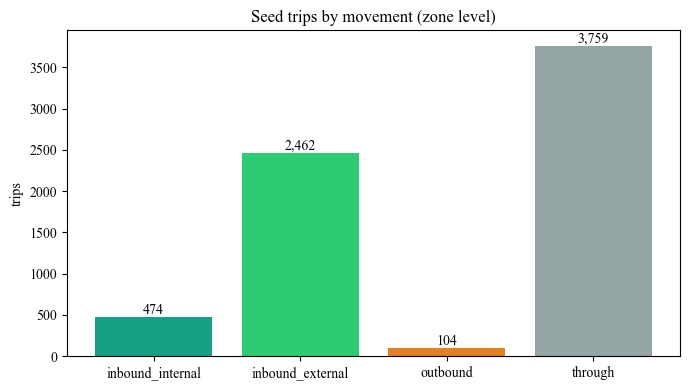

 saved 03_f1_movement.png


In [14]:
# Define a helper function to apply tight layout, save the figure to the FIGURES directory, and display it
def _save(name): plt.tight_layout(); plt.savefig(FIGURES/name, dpi=150, bbox_inches="tight"); plt.show(); print(" saved", name)

# Set the global font family to Times New Roman for the plot
plt.rcParams["font.family"] = "Times New Roman"

# Define a consistent colour palette for the four movement categories
MV_COL = {"inbound_internal":"#16a085","inbound_external":"#2ecc71","outbound":"#e67e22","through":"#95a5a6"}

# Group the snapped OD data by movement type, sum the trips, enforce a consistent category order, and fill missing values with 0
mv = od_zones.groupby("movement").trips.sum().reindex(["inbound_internal","inbound_external","outbound","through"]).fillna(0)

# Initialise the matplotlib figure and axes with a specific size and white background
fig, ax = plt.subplots(figsize=(7,4)); fig.patch.set_facecolor("white")

# Generate the bar chart using the defined colour palette
b = ax.bar(mv.index, mv.values, color=[MV_COL[m] for m in mv.index])

# Iterate through the bars to attach data labels showing the trip totals above each bar
for bar,v in zip(b, mv.values): ax.text(bar.get_x()+bar.get_width()/2, v, f"{v:,.0f}", ha="center", va="bottom")

# Apply axis labels and a title to the chart
ax.set_ylabel("trips")
ax.set_title("Seed trips by movement (zone level)")

# Save the generated plot using the helper function
_save("03_f1_movement.png")

## Key results

End-of-notebook summary of the seed matrix handed to Notebook 04.


In [16]:
# End-of-run key-results printout (recomputed from the in-memory tables).
print("NOTEBOOK 03 - OD SEED: KEY RESULTS")
print("=" * 50)
print(f"Zones: {len(sa1_codes)} SA1 inside | {len(dzn_codes_inside)} DZN inside | "
      f"{len(sa2)} SA2 outside | {len(dzn_codes_outside)} DZN outside | {len(entries)} entry points")
print("Snapped OD + raw through (trips):")
for mv in ["inbound_internal", "inbound_external", "outbound"]:
    s = od_snapped[od_snapped.movement == mv]
    print(f"  {mv:17s}: {len(s):>5,} rows  {s.trips.sum():>7,.0f} trips")
print(f"  {'through (raw)':17s}: {len(od_sa2_thru):>5,} rows  {od_sa2_thru.trips.sum():>7,.0f} trips")
print(f"Conservation: snapped + through = {od_snapped.trips.sum() + od_sa2_thru.trips.sum():,.0f} "
      f"= zone OD {od_zones.trips.sum():,.0f}")
print("Outputs: jtw_2016_bike_od_snapped.csv, jtw_2016_bike_od_through_raw.csv, "
      "jtw_2016_points.csv, jtw_2016_zone_centroids.csv")


NOTEBOOK 03 - OD SEED: KEY RESULTS
Zones: 556 SA1 inside | 292 DZN inside | 563 SA2 outside | 1941 DZN outside | 30 entry points
Snapped OD + raw through (trips):
  inbound_internal :   121 rows      474 trips
  inbound_external : 1,443 rows    2,462 trips
  outbound         :    26 rows      104 trips
  through (raw)    :   765 rows    3,759 trips
Conservation: snapped + through = 6,799 = zone OD 6,799
Outputs: jtw_2016_bike_od_snapped.csv, jtw_2016_bike_od_through_raw.csv, jtw_2016_points.csv, jtw_2016_zone_centroids.csv
